In [45]:
#Importing libraries

In [46]:
import pandas as pd
import matplotlib.pyplot as plt

In [47]:
#Importing data

In [48]:
sales = pd.read_csv("../data/sales_daily.csv", parse_dates=["date"])
products = pd.read_csv("../data/products.csv", parse_dates=["launch_date", "end_of_life_date"])
calendar = pd.read_csv("../data/marketing_calendar.csv", parse_dates=["start_date", "end_date"])

print("sales:   ", sales.shape)
print("products:", products.shape)
print("calendar:", calendar.shape)

sales:    (36775, 10)
products: (40, 13)
calendar: (4, 5)


In [49]:
#Data exploration:

In [50]:
#let's look at the table structure

In [51]:
sales.head()

,date,sku,units_sold,list_price_eur,discount_pct,selling_price_eur,campaign_id,stock_end_of_day,stockout_flag,revenue_eur
0,2023-09-04,SKU001,9,299.0,0.0,299.0,NaN,555,0,2691.0
1,2023-09-05,SKU001,7,299.0,0.0,299.0,NaN,548,0,2093.0
2,2023-09-06,SKU001,6,299.0,0.0,299.0,NaN,542,0,1794.0
3,2023-09-07,SKU001,2,299.0,0.0,299.0,NaN,540,0,598.0
4,2023-09-08,SKU001,6,299.0,0.0,299.0,NaN,534,0,1794.0


In [52]:
products.head()

,sku,product_name,category,supplier_id,family,predecessor_sku,launch_date,end_of_life_date,launch_price_eur,moq_units,case_pack_units,unit_cost_eur,q4_2026_allocation_units
0,SKU001,Noise-Cancelling Headphones Gen 1,Audio,SUP02,HEADPHONES,NaN,2023-09-04,2025-04-30,299,60,6,182.40,NaN
1,SKU002,Noise-Cancelling Headphones Gen 2,Audio,SUP02,HEADPHONES,SKU001,2025-04-07,2026-10-31,329,70,10,197.72,NaN
2,SKU003,Noise-Cancelling Headphones Gen 3,Audio,SUP02,HEADPHONES,SKU002,2026-09-21,NaT,349,66,6,203.13,336.0
3,SKU004,Wireless Earbuds Gen 1,Audio,SUP02,EARBUDS,NaN,2023-10-02,2025-10-31,149,140,10,97.27,NaN
4,SKU005,Wireless Earbuds Gen 2,Audio,SUP02,EARBUDS,SKU004,2025-09-22,NaT,169,90,10,121.01,520.0


In [53]:
calendar.head()

,event,year,start_date,end_date,status
0,Black Week,2023,2023-11-20,2023-11-27,completed
1,Black Week,2024,2024-11-25,2024-12-02,completed
2,Black Week,2025,2025-11-24,2025-12-01,completed
3,Black Week,2026,2026-11-23,2026-11-30,planned


In [54]:
#We check how many products for category

In [55]:
products.category.value_counts()

category
Computing & Mobile    13
TV & Smart Home       11
Audio                  7
Gaming                 5
Wearables              4
Name: count, dtype: int64

In [56]:
#We agregate sales per week

In [57]:
weekly = sales.set_index("date").units_sold.resample("W").sum()


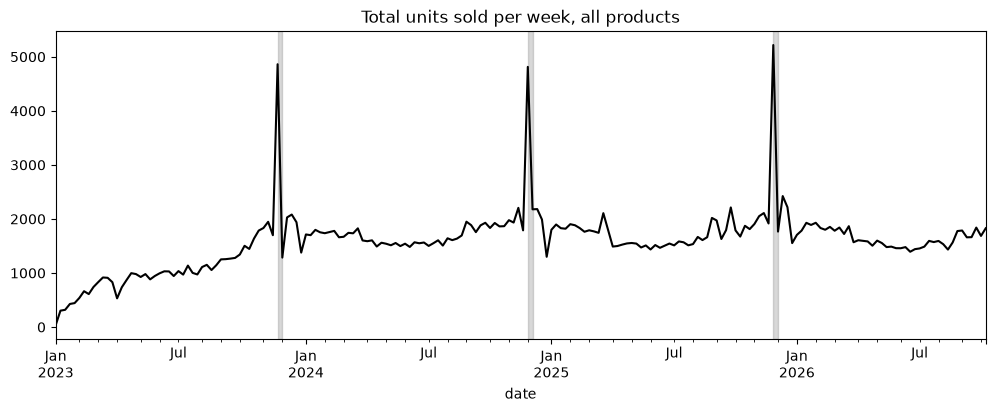

In [58]:
ax = weekly.plot(figsize=(12, 4), color="black", title="Total units sold per week, all products")
for row in calendar[calendar.status == "completed"].itertuples():
    ax.axvspan(row.start_date, row.end_date, color="grey", alpha=0.3)
plt.show()

In [59]:
#First week has very low values because it does not contain 7 days

In [60]:
for row in calendar[calendar.status == "completed"].itertuples():
    units = sales[sales.date.between(row.start_date, row.end_date)].units_sold.sum()
    print(row.year, f"{units:,} units")

2023 5,385 units
2024 5,491 units
2025 5,892 units


In [61]:
#Checking one sku

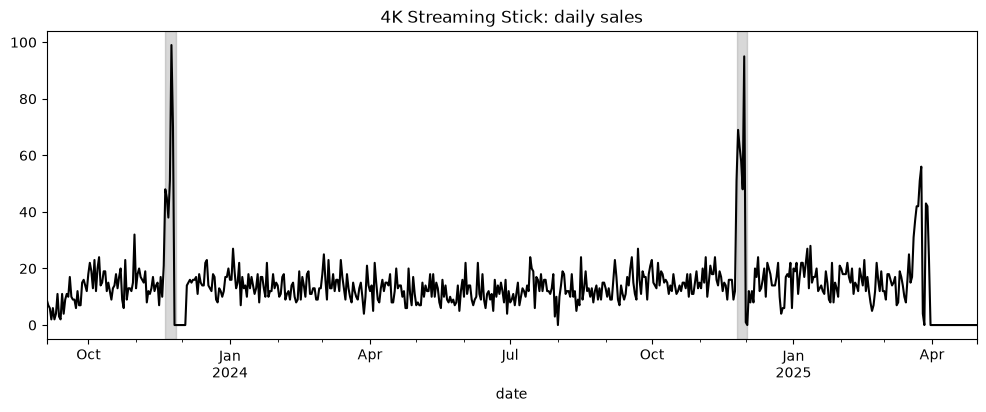

In [62]:
one = sales[sales.sku == "SKU001"].set_index("date")

ax = one.units_sold.plot(figsize=(12, 4), color="black", title="4K Streaming Stick: daily sales")
for row in calendar[calendar.status == "completed"].itertuples():
    ax.axvspan(row.start_date, row.end_date, color="grey", alpha=0.3)
plt.show()

In [63]:
#each calendar row  to be identified by year

In [64]:
calendar = calendar.set_index("year")
print(calendar)


           event start_date   end_date     status
year                                             
2023  Black Week 2023-11-20 2023-11-27  completed
2024  Black Week 2024-11-25 2024-12-02  completed
2025  Black Week 2025-11-24 2025-12-01  completed
2026  Black Week 2026-11-23 2026-11-30    planned


In [65]:
calendar.loc[2024, "start_date"]

Timestamp('2024-11-25 00:00:00')

In [66]:
#important to filter out the SKUs that were in the previous black weeks on sale

In [67]:
in_bw_2023 = sales.date.between(calendar.loc[2023, "start_date"], calendar.loc[2023, "end_date"])
in_bw_2024 = sales.date.between(calendar.loc[2024, "start_date"], calendar.loc[2024, "end_date"])
in_bw_2025 = sales.date.between(calendar.loc[2025, "start_date"], calendar.loc[2025, "end_date"])
bw_sales = sales[in_bw_2023 | in_bw_2024 | in_bw_2025]

In [68]:
#on sale all 24 black week days in the past

In [69]:
days_on_sale = bw_sales.groupby("sku").date.nunique()
full_history = days_on_sale[days_on_sale == 24].index


In [70]:
scope = products[products.sku.isin(full_history) & products.end_of_life_date.isna()]
print(len(scope), "products in scope")
scope[["sku", "product_name"]]


21 products in scope


,sku,product_name
5,SKU006,Portable Bluetooth Speaker
10,SKU011,Fitness Band
14,SKU015,4K Streaming Stick
19,SKU020,Video Doorbell
20,SKU021,Indoor Security Camera
21,SKU022,Smart Plug 2-Pack
22,SKU023,Wireless Game Controller
25,SKU026,Mechanical Keyboard
26,SKU027,Gaming Mouse
27,SKU028,E-Reader


In [71]:
##Prepare the data for Prophet

In [72]:
#One product in prophets format
product = sales[sales.sku == "SKU015"]
df = product[["date", "units_sold"]].rename(columns={"date": "ds", "units_sold": "y"})
df.head()

,ds,y
8147,2023-01-01,19
8148,2023-01-02,31
8149,2023-01-03,29
8150,2023-01-04,37
8151,2023-01-05,34


In [73]:
#now we create the events table 

In [74]:
events = pd.DataFrame({
    "holiday": "black_week",
    "ds": calendar.start_date,
    "lower_window": 0,
    "upper_window": 7,
})
events

,holiday,ds,lower_window,upper_window
year,,,,
2023,black_week,2023-11-20,0,7
2024,black_week,2024-11-25,0,7
2025,black_week,2025-11-24,0,7
2026,black_week,2026-11-23,0,7


In [75]:
#defining the cutoff day / last day of historical data


In [76]:
cutoff = pd.Timestamp("2025-10-12")
train = df[df.ds < cutoff]
print("Training data from", train.ds.min().date(), "to", train.ds.max().date())

Training data from 2023-01-01 to 2025-10-11


In [77]:
# last year benchmark as actual to compare

In [78]:
bw_2024_days = pd.date_range(calendar.loc[2024, "start_date"], calendar.loc[2024, "end_date"])
bw_2025_days = pd.date_range(calendar.loc[2025, "start_date"], calendar.loc[2025, "end_date"])

In [79]:
benchmark = df[df.ds.isin(bw_2024_days)].y.sum()
print("Benchmark (Black Week 2024):", benchmark)

Benchmark (Black Week 2024): 595


In [80]:
actual = df[df.ds.isin(bw_2025_days)].y.sum()
print("Actual (Black Week 2025):", actual)

Actual (Black Week 2025): 657


In [81]:
#what is the distance

In [82]:
error = (benchmark - actual) / actual * 100
print(f"Benchmark error: {error:.0f}%")

Benchmark error: -9%


In [83]:
#Prophet forecast

In [84]:
from prophet import Prophet

In [85]:
model = Prophet()
model.fit(train)

19:37:20 - cmdstanpy - INFO - Chain [1] start processing
19:37:20 - cmdstanpy - INFO - Chain [1] done processing


In [86]:
future = model.make_future_dataframe(periods=81)
forecast = model.predict(future)

In [87]:
no_events = forecast[forecast.ds.isin(bw_2025_days)].yhat.sum()
print(f"Prophet without events: {no_events:.0f} units")

Prophet without events: 422 units


In [88]:
model_bw = Prophet(holidays=events)
model_bw.fit(train)
forecast_bw = model_bw.predict(future)

with_events = forecast_bw[forecast_bw.ds.isin(bw_2025_days)].yhat.sum()
print(f"Prophet with Black Week: {with_events:.0f} units")



19:40:35 - cmdstanpy - INFO - Chain [1] start processing
19:40:35 - cmdstanpy - INFO - Chain [1] done processing


Prophet with Black Week: 688 units


In [91]:
bw_2023_days = pd.date_range(calendar.loc[2023, "start_date"], calendar.loc[2023, "end_date"])

avg_2y = (df[df.ds.isin(bw_2023_days)].y.sum() + df[df.ds.isin(bw_2024_days)].y.sum()) / 2
error_avg = (avg_2y - actual) / actual * 100
print(f"Average of 2023 and 2024: {avg_2y:.0f} units, error {error_avg:.0f}%")

Average of 2023 and 2024: 686 units, error 4%
